# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
# Установка зависимостей при необходимости (один раз):
# %pip install -r requirements.txt

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (len(X),) or not len(X):
            raise ValueError('Ожидаются X: (N, d), y: (N,), N > 0')
        if not np.isfinite(X).all() or not np.isin(y, [0, 1]).all():
            raise ValueError('Нужны конечные признаки и метки 0/1')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError('gd_type: full или stochastic')
        if self.max_iter < 1 or self.batch_size < 1 or self.eta <= 0 or self.tolerance < 0:
            raise ValueError('Некорректные параметры оптимизации')
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        X = np.column_stack([np.ones(len(X)), X])
        self.w = np.zeros(X.shape[1]) if self.w0 is None else np.array(self.w0, dtype=float, copy=True)
        if self.w.shape != (X.shape[1],) or not np.isfinite(self.w).all():
            raise ValueError('w0 должен иметь размер d+1 и конечные значения')
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        self.stop_reason_ = 'max_iter'
        for iteration in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X, y)
            else:
                idx = rng.choice(len(X), size=min(self.batch_size, len(X)), replace=False)
                gradient = self.calc_gradient(X[idx], y[idx])
            step = self.eta * gradient
            self.w -= step
            self.n_iter_ = iteration + 1
            if np.linalg.norm(step) < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break
        self.intercept_ = self.w[:1].copy()
        self.coef_ = self.w[None, 1:].copy()
        return self

    def sigmoid(self, z):
        return np.exp(-np.logaddexp(0, -np.asarray(z, dtype=float)))

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != len(self.w)-1 or not np.isfinite(X).all():
            raise ValueError('Некорректная матрица признаков')
        X = np.column_stack([np.ones(len(X)), X])
        p = self.sigmoid(X @ self.w)
        return np.column_stack([1-p, p])

    def predict(self, X, threshold=0.5):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        if not 0 <= threshold <= 1:
            raise ValueError('Порог должен быть от 0 до 1')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        # Эквивалент log-loss, устойчивый даже при больших по модулю логитах.
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, (1-2*y)*z)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=42):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.41e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,iterations,stop
GD,1000,max_iter
SGD,1000,max_iter


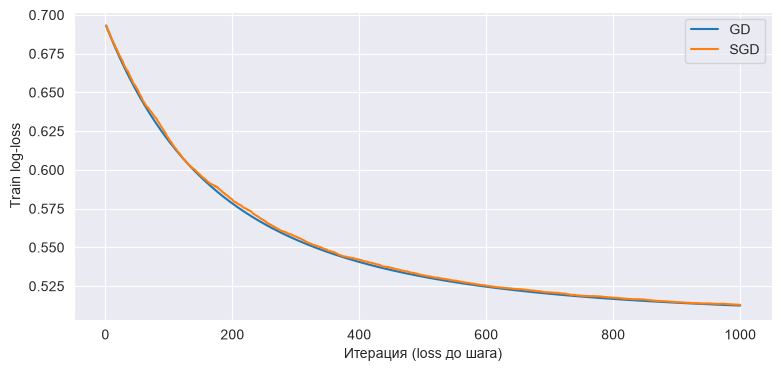

In [6]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
display(pd.DataFrame({'iterations': [gd.n_iter_, sgd.n_iter_],
                      'stop': [gd.stop_reason_, sgd.stop_reason_]}, index=['GD', 'SGD']))
plt.figure(figsize=(9, 4))
for name, model in [('GD', gd), ('SGD', sgd)]:
    plt.plot(np.arange(1, model.n_iter_+1), model.loss_history, label=name)
plt.xlabel('Итерация (loss до шага)'); plt.ylabel('Train log-loss'); plt.legend(); plt.show()

Обе модели остановились по max_iter после 1000 шагов.

Градиент: $\nabla Q(w)=X^T(\sigma(Xw)-y)/N$, где первый столбец $X$ состоит из единиц.

Оба критерия проверяются на каждом шаге: остановка наступает при выполнении любого из них. Фактическая причина и число шагов приведены в таблице. GD даёт более гладкое снижение loss; SGD шумит из-за случайного состава батча. При постоянном шаге шум градиента не исчезает даже около оптимума, поэтому малую норму изменения весов получить трудно. Для **градиента** GD просматривает 14 000 объектов, SGD — 32. Однако по условию loss на каждом шаге вычисляется на всех 14 000 объектах, поэтому эта реализация SGD не имеет обычного выигрыша по полной стоимости итерации.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

,eta,final_loss,iterations,stop
0,0.001,0.618087,1000,max_iter
1,0.010,0.512435,1000,max_iter
2,0.100,0.505762,465,tolerance
3,1.000,0.505757,70,tolerance
4,10.000,0.901345,1000,max_iter


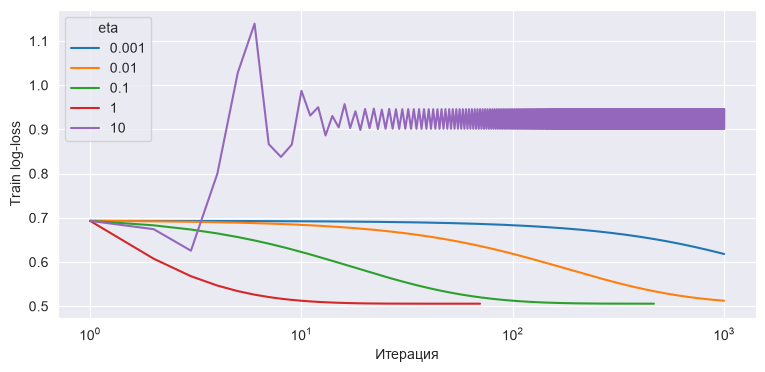

In [7]:
eta_models = {}
rows = []
plt.figure(figsize=(9, 4))
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(eta=eta).fit(X_train, y_train)
    eta_models[eta] = model
    rows.append({'eta': eta, 'final_loss': model.calc_loss(np.c_[np.ones(len(X_train)), X_train], y_train),
                 'iterations': model.n_iter_, 'stop': model.stop_reason_})
    plt.plot(np.arange(1, model.n_iter_+1), model.loss_history, label=str(eta))
display(pd.DataFrame(rows))
plt.xscale('log'); plt.xlabel('Итерация'); plt.ylabel('Train log-loss'); plt.legend(title='eta'); plt.show()

Численно: eta=0.1 сошёлся за 465 шагов, eta=1 — за 70; loss около 0.50576. При eta=10 итоговый loss вырос до 0.90135.

Малый шаг даёт медленное продвижение: за ограниченное число итераций модель может не дойти до минимума. Умеренное увеличение шага ускоряет сходимость. Слишком большой шаг перескакивает через минимум, вызывая колебания и увеличение loss (здесь это видно для eta=10). Важно сравнивать сам loss, а не только число шагов: критерий по изменению весов зависит от eta, поэтому маленький шаг может формально удовлетворить tolerance далеко от оптимума.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sk_synth = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
display(pd.DataFrame({name: {'accuracy': metrics.accuracy_score(y_test, m.predict(X_test)),
    'ROC-AUC': metrics.roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])}
    for name, m in [('GD', gd), ('SGD', sgd), ('sklearn', sk_synth)]}).T)
w_sk = np.r_[sk_synth.intercept_, sk_synth.coef_.ravel()]
display(pd.DataFrame({'GD': gd.w, 'sklearn': w_sk, 'difference': gd.w-w_sk}))
print('L2 разности весов:', np.linalg.norm(gd.w-w_sk))

,accuracy,ROC-AUC
GD,0.7820,0.838787
SGD,0.7825,0.838115
sklearn,0.7765,0.838676


,GD,sklearn,difference
0,-0.002114,-0.021880,0.019765
1,0.006076,0.002741,0.003335
2,0.006963,0.009039,-0.002077
3,-0.547170,-0.722690,0.175520
4,-0.144536,-0.262335,0.117799
5,0.012487,0.016588,-0.004102
6,-0.006325,-0.011488,0.005163
7,0.000814,0.005587,-0.004773
8,0.039084,0.057188,-0.018104
9,-0.002425,-0.001239,-0.001185


L2 разности весов: 0.3567832506090773


Метрики близки, но точного совпадения весов и метрик нет. Наши методы ограничены числом шагов и tolerance, а sklearn использует другой оптимизатор (lbfgs). Кроме того, по умолчанию sklearn добавляет L2-регуляризацию с C=1. Для той же нерегуляризованной задачи в используемой версии можно задать `LogisticRegression(C=np.inf, max_iter=10000, tol=1e-9)` (в версиях с соответствующим API — `penalty=None`). Даже тогда из-за линейно зависимых признаков синтетической задачи веса могут быть неединственны, хотя предсказания совпадают.

Источник: [документация LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
from pathlib import Path
df_raw = pd.read_csv(Path('Data') / 'wine_quality.csv')
print('Исходные данные:', df_raw.shape)
print('Пропуски:', df_raw.isna().sum().to_dict())
print('Полные дубликаты:', df_raw.duplicated().sum())
# Нет идентификатора образца: консервативно считаем полные повторы дубликатами.
# Удаляем до разбиения, чтобы одинаковые строки не попали в train и test.
df = df_raw.drop_duplicates().reset_index(drop=True)
print('После удаления повторов:', df.shape)
df.head()

Исходные данные: (6497, 13)
Пропуски: {'fixed_acidity': 0, 'volatile_acidity': 0, 'citric_acid': 0, 'residual_sugar': 0, 'chlorides': 0, 'free_sulfur_dioxide': 0, 'total_sulfur_dioxide': 0, 'density': 0, 'pH': 0, 'sulphates': 0, 'alcohol': 0, 'is_red': 0, 'target': 0}
Полные дубликаты: 1177
После удаления повторов: (5320, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Prevalence train / test:', y_train.mean(), y_test.mean())
baseline = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
baseline.fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
y_pred = (p_base >= 0.5).astype(int)
display(pd.DataFrame({'accuracy': [metrics.accuracy_score(y_test, np.zeros(len(y_test))),
                                 metrics.accuracy_score(y_test, y_pred)]}, index=['always 0', 'LogisticRegression']))

Prevalence train / test: 0.1895810955961332 0.18984962406015038


,accuracy
always 0,0.810150
LogisticRegression,0.815163


Пропусков нет. Удалено 1177 повторов. Prevalence: train 0.18958, test 0.18985. Accuracy константы 0.81015, LR 0.81516 — выигрыш всего около 0.005.

Пропуски и полные повторы посчитаны перед разбиением. Полные дубликаты удалены: без идентификатора вина нельзя установить, являются ли они независимыми измерениями, поэтому это консервативная защита от утечки одинаковых объектов между train и test. Если бы независимость повторов была подтверждена, их можно было бы оставить; для повторных измерений одного вина нужно групповое разбиение. Все дальнейшие результаты относятся к данным без полных повторов. `stratify=y` сохраняет близкие доли классов. Константная модель получает высокую accuracy за счёт большинства, но не находит ни одного хорошего вина; accuracy скрывает эту проблему.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

{'TP': 92, 'TN': 1209, 'FP': 84, 'FN': 211}


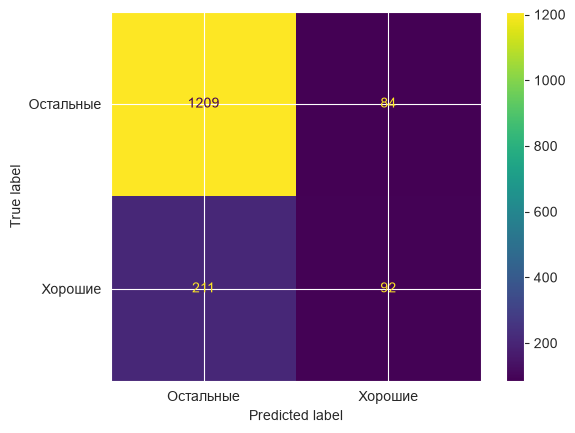

Чаще встречается: FN


In [12]:
truth = y_test.to_numpy()
TP = int(np.sum((truth == 1) & (y_pred == 1)))
TN = int(np.sum((truth == 0) & (y_pred == 0)))
FP = int(np.sum((truth == 0) & (y_pred == 1)))
FN = int(np.sum((truth == 1) & (y_pred == 0)))
cm = np.array([[TN, FP], [FN, TP]])
assert np.array_equal(cm, metrics.confusion_matrix(y_test, y_pred))
print(dict(TP=TP, TN=TN, FP=FP, FN=FN))
metrics.ConfusionMatrixDisplay(cm, display_labels=['Остальные', 'Хорошие']).plot(); plt.show()
print('Чаще встречается:', 'FN' if FN > FP else 'FP' if FP > FN else 'одинаково')

FP — посредственное вино ошибочно рекомендовано клиенту; FN — хорошее вино пропущено. При пороге 0.5 модель пропускает больше хороших вин, чем ошибочно рекомендует плохих (сравнение счётчиков приведено выше).

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP+FP) if TP+FP else 0.
recall = TP / (TP+FN) if TP+FN else 0.
def fbeta_formula(beta):
    denominator = beta**2 * precision + recall
    return (1+beta**2)*precision*recall/denominator if denominator else 0.
manual = [precision, recall, fbeta_formula(1), fbeta_formula(.5), fbeta_formula(2)]
reference = [metrics.precision_score(y_test, y_pred, zero_division=0),
             metrics.recall_score(y_test, y_pred, zero_division=0)] + [
             metrics.fbeta_score(y_test, y_pred, beta=b, zero_division=0) for b in [1, .5, 2]]
assert np.allclose(manual, reference)
display(pd.DataFrame({'manual': manual, 'sklearn': reference}, index=['precision','recall','F1','F0.5','F2']))

,manual,sklearn
precision,0.522727,0.522727
recall,0.303630,0.303630
F1,0.384134,0.384134
F0.5,0.456802,0.456802
F2,0.331412,0.331412


Precision — доля хороших вин среди рекомендованных, recall — доля найденных хороших вин среди всех действительно хороших. F1 симметрично учитывает precision и recall; F0.5 сильнее учитывает precision, F2 — recall. Для сервиса, берегущего доверие клиентов, подходит F0.5; для «самой широкой подборки» — F2 или максимизация precision при заданном минимальном recall. Метрика сама по себе не задаёт денежную стоимость ошибок.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

GD: 15318 tolerance
Норма градиента: 4.997646692264532e-06


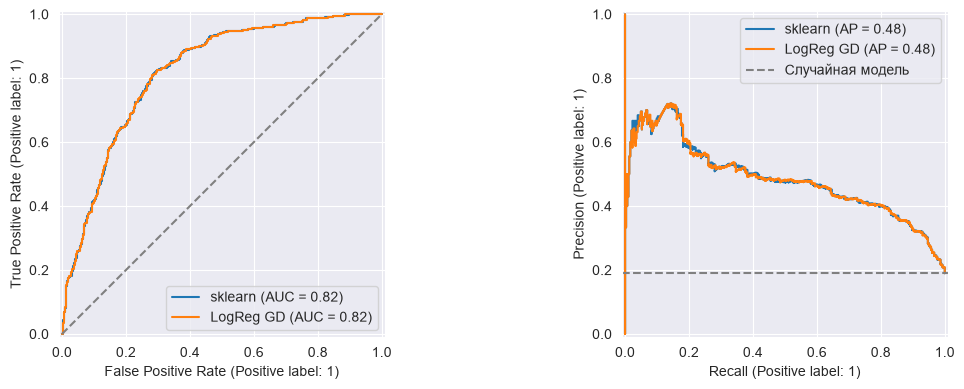

,ROC-AUC,PR-AUC (AP)
sklearn,0.820876,0.484766
LogReg GD,0.820562,0.483759


Лидер ROC-AUC: sklearn ; лидер AP: sklearn


p               0.820876
10p             0.820876
p^3             0.820876
logit(p)        0.820876
-p              0.179124
class labels    0.619333
Name: ROC-AUC, dtype: float64

In [14]:
# Выбор параметров по сходимости TRAIN, без обращения к test.
wine_scaler = StandardScaler().fit(X_train)
wine_train_scaled = wine_scaler.transform(X_train)
wine_gd = LogReg(eta=0.2, max_iter=20000, tolerance=1e-6).fit(wine_train_scaled, y_train.to_numpy())
print('GD:', wine_gd.n_iter_, wine_gd.stop_reason_)
print('Норма градиента:', np.linalg.norm(wine_gd.calc_gradient(np.c_[np.ones(len(X_train)), wine_train_scaled], y_train.to_numpy())))
p_gd = wine_gd.predict_proba(wine_scaler.transform(X_test))[:, 1]
scores = {'sklearn': p_base, 'LogReg GD': p_gd}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, prob in scores.items():
    metrics.RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[1].axhline(y_test.mean(), ls='--', color='gray', label='Случайная модель')
axes[1].legend(); plt.tight_layout(); plt.show()
auc_table = pd.DataFrame({name: {'ROC-AUC': metrics.roc_auc_score(y_test, prob),
    'PR-AUC (AP)': metrics.average_precision_score(y_test, prob)} for name, prob in scores.items()}).T
display(auc_table)
print('Лидер ROC-AUC:', auc_table['ROC-AUC'].idxmax(), '; лидер AP:', auc_table['PR-AUC (AP)'].idxmax())
p = np.clip(p_base, 1e-15, 1-1e-15)
display(pd.Series({name: metrics.roc_auc_score(y_test, s) for name, s in
    {'p': p, '10p': 10*p, 'p^3': p**3, 'logit(p)': np.log(p/(1-p)), '-p': -p,
     'class labels': y_pred}.items()}, name='ROC-AUC'))

В этом запуске sklearn лучше по обеим метрикам: ROC-AUC 0.82088 и AP 0.48477 против 0.82056 и 0.48376 у LogReg. GD остановился по tolerance за 15318 шагов.

Лидеры по двум метрикам указаны под таблицей; различия небольшие, поскольку модели решают близкие задачи. Без оценки неопределённости нельзя утверждать значимое превосходство. ROC-AUC зависит от порядка score: строго возрастающие преобразования 10p, p³ и logit сохраняют его, а смена знака обращает ранжирование и даёт 1−AUC (с учётом половины веса ничьих). Метки классов тоже допустимы, но теряют ранжирование внутри двух групп: получается AUC=(TPR+TNR)/2, а ROC имеет только одну нетривиальную точку. Уровень precision случайного отбора равен prevalence теста, а не 0.5, поскольку классы несбалансированы; это также ориентир AP для большой случайной выборки. `average_precision_score` — ступенчатая взвешенная средняя precision, а не трапециевидный интеграл PR-кривой.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

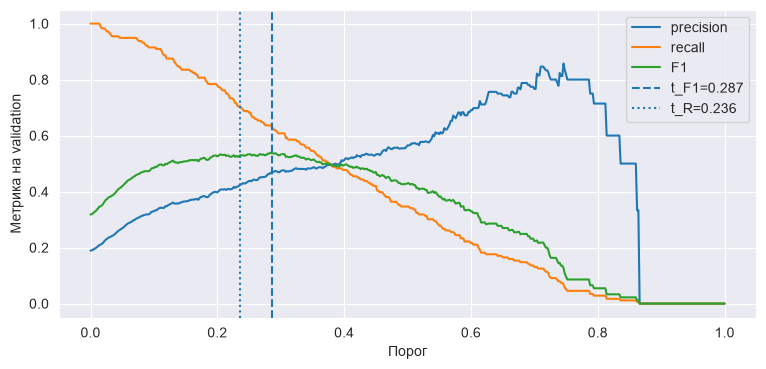

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
LR 0.5,0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
LR t_F1,0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
LR t_R,0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


На тесте recall >= .7: True
Выбранные пороги: {'t_F1': 0.28654953755693174, 't_R': 0.23635860938278658}


In [15]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=.25,
    stratify=y_train, random_state=RANDOM_STATE)
val_model = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE)).fit(X_fit, y_fit)
p_val = val_model.predict_proba(X_val)[:, 1]
# Все различные решения, а не только грубая сетка порогов.
vp, vr, vt = metrics.precision_recall_curve(y_val, p_val)
vf = np.divide(2*vp[:-1]*vr[:-1], vp[:-1]+vr[:-1], out=np.zeros_like(vt), where=(vp[:-1]+vr[:-1])>0)
t_f1 = float(vt[np.argmax(vf)])
eligible = np.flatnonzero(vr[:-1] >= .7)
t_r = float(vt[eligible[np.argmax(vp[:-1][eligible])]])
threshold_grid = np.linspace(0, 1, 501)
grid_values = np.array([[metrics.precision_score(y_val, p_val>=t, zero_division=0),
    metrics.recall_score(y_val, p_val>=t, zero_division=0), metrics.f1_score(y_val, p_val>=t, zero_division=0)] for t in threshold_grid])
plt.figure(figsize=(9, 4))
for j, name in enumerate(['precision', 'recall', 'F1']):
    plt.plot(threshold_grid, grid_values[:, j], label=name)
plt.axvline(t_f1, ls='--', label=f't_F1={t_f1:.3f}')
plt.axvline(t_r, ls=':', label=f't_R={t_r:.3f}')
plt.xlabel('Порог'); plt.ylabel('Метрика на validation'); plt.legend(); plt.show()
baseline.fit(X_train, y_train)
def evaluate(model, threshold=.5):
    prob = model.predict_proba(X_test)[:, 1]
    pred = prob >= threshold
    return {'threshold': threshold, 'accuracy': metrics.accuracy_score(y_test, pred),
        'precision': metrics.precision_score(y_test, pred, zero_division=0),
        'recall': metrics.recall_score(y_test, pred, zero_division=0),
        'F1': metrics.f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_test, prob), 'PR-AUC': metrics.average_precision_score(y_test, prob)}
threshold_results = pd.DataFrame({name: evaluate(baseline, t) for name, t in [('LR 0.5', .5), ('LR t_F1', t_f1), ('LR t_R', t_r)]}).T
display(threshold_results)
print('На тесте recall >= .7:', threshold_results.loc['LR t_R', 'recall'] >= .7)
print('Выбранные пороги:', {'t_F1': t_f1, 't_R': t_r})

Получены t_F1=0.28655 и t_R=0.23636. Для t_R на тесте precision=0.42126, recall=0.70627, F1=0.52774: ограничение recall ≥ 0.7 выполнено.

Выполнение ограничения на тесте явно проверено выше. Валидация конечна, состав новых объектов отличается; кроме того, после переобучения на всём train вероятности могут немного измениться. Поэтому recall≥0.7 на validation не является гарантией для test. Для заявленного ограничения сервиса выбираю обычную LR и t_R: этот порог максимизирует precision среди допустимых на validation. Решение фиксируется здесь, до сравнения балансировок на тесте. Если ограничение должно выполняться с высокой вероятностью, нужен запас по recall и оценка его неопределённости на отдельной валидации, а не дополнительная подгонка по тесту.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
balanced = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE)).fit(X_train, y_train)
counts = y_train.value_counts().sort_index()
display(pd.DataFrame({'count': counts, 'class_weight': len(y_train)/(2*counts)}))
models = {'LR': baseline, 'balanced': balanced}
comparison = pd.DataFrame({name: evaluate(model) for name, model in models.items()}).T
display(comparison)
display(comparison.loc['balanced'] - comparison.loc['LR'])

,count,class_weight
target,,
0,3018,0.616965
1,706,2.637394


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
LR,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


threshold    0.000000
accuracy    -0.080827
precision   -0.124067
recall       0.481848
F1           0.144755
ROC-AUC      0.000059
PR-AUC      -0.003619
dtype: float64

Вес класса k равен n/(K·n_k), здесь K=2. Поэтому суммарный вес каждого класса одинаков, а редкие хорошие вина получают больший вес. При пороге 0.5 обычно сильно растёт recall и снижается precision: модель чаще выбирает класс 1. Accuracy также может уменьшиться. Ранжирующие метрики ROC-AUC и AP изменяются слабее, чем пороговые, поскольку многие относительные порядки объектов сохраняются; точные изменения показаны отдельной строкой. Взвешивание меняет целевую функцию, поэтому это не строго эквивалентно смене порога.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.base import clone
samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}
resampled_counts = {}
for name, sampler in samplers.items():
    model = make_imb_pipeline(StandardScaler(), clone(sampler), LogisticRegression(random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    models[name] = model
    # Отдельная воспроизводимая проверка размеров; test сюда не передаётся.
    _, yr = clone(sampler).fit_resample(model.steps[0][1].transform(X_train), y_train)
    resampled_counts[name] = pd.Series(yr).value_counts().sort_index()
display(pd.DataFrame(resampled_counts).T.rename(columns={0:'class 0', 1:'class 1'}))
comparison = pd.DataFrame({name: evaluate(model) for name, model in models.items()}).T
display(comparison)
resampling_results = comparison.loc[list(samplers)]
print('Лучший AP:', resampling_results['PR-AUC'].idxmax(), '; худший AP:', resampling_results['PR-AUC'].idxmin())
reverse_smote = make_imb_pipeline(SMOTE(random_state=RANDOM_STATE), StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)).fit(X_train, y_train)
display(pd.DataFrame({'scale → SMOTE': evaluate(models['SMOTE']), 'SMOTE → scale': evaluate(reverse_smote)}).T)

target,class 0,class 1
RandomUnderSampler,706,706
NearMiss,706,706
RandomOverSampler,3018,3018
SMOTE,3018,3018


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
LR,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
RandomUnderSampler,0.5,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss,0.5,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
RandomOverSampler,0.5,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


Лучший AP: RandomOverSampler ; худший AP: NearMiss


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
scale → SMOTE,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
SMOTE → scale,0.5,0.739348,0.402418,0.768977,0.528345,0.821629,0.485152


Среди четырёх основных ресемплеров лучший AP у RandomOverSampler (0.48108), худший у NearMiss (0.44790). При перестановке SMOTE и scaler AP изменился с 0.47961 до 0.48515.

Пайплайн imblearn умеет вызывать `fit_resample` при обучении; обычный sklearn Pipeline требует промежуточные трансформеры. При predict этап ресемплинга пропускается, test не меняет размер и распределение. Балансировка до split создаёт утечку (копии или близкие синтетические объекты оказываются по обе стороны) и нереалистично меняет долю классов теста.

Лучший и худший методы по тестовому AP указаны выше; это описательное сравнение, а не основание переобучать выбранную модель. Undersampling теряет данные; NearMiss целенаправленно меняет состав большинства и может исказить границу. Oversampling сохраняет все исходные наблюдения, SMOTE добавляет интерполяции, которые не обязательно соответствуют реальным винам (в частности, is_red может стать дробным). Эти механизмы объясняют возможные различия, но не доказывают их причину.

Для NearMiss и SMOTE масштабирование **до** ресемплинга существенно: оно меняет расстояния и соседей. RandomUnderSampler и RandomOverSampler выбирают индексы независимо от масштаба, поэтому сам набор выбранных объектов не меняется. Однако scaler, обученный до или после ресемплинга, имеет разные средние и дисперсии; при L2-регуляризации даже для случайных методов итоговая модель может отличаться. Проверка перестановки шагов для SMOTE приведена в таблице.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
balanced 0.5,0.50000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
LR t_F1,0.28655,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


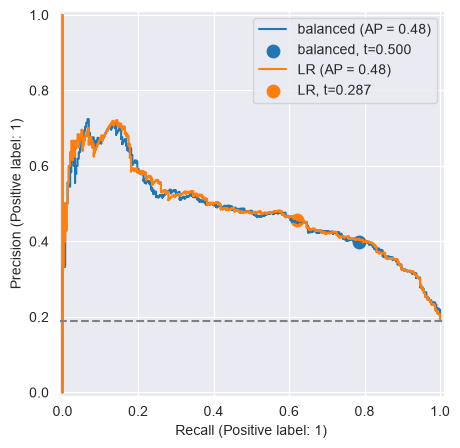

In [18]:
display(pd.DataFrame({'balanced 0.5': evaluate(balanced), 'LR t_F1': evaluate(baseline, t_f1)}).T)
fig, ax = plt.subplots(figsize=(7, 5))
for name, model, threshold in [('balanced', balanced, .5), ('LR', baseline, t_f1)]:
    prob = model.predict_proba(X_test)[:, 1]
    metrics.PrecisionRecallDisplay.from_predictions(y_test, prob, ax=ax, name=name)
    result = evaluate(model, threshold)
    ax.scatter(result['recall'], result['precision'], s=80, label=f'{name}, t={threshold:.3f}')
ax.axhline(y_test.mean(), ls='--', color='gray'); ax.legend(); plt.show()

PR-кривые близки, а рабочие точки могут заметно отличаться. Смена порога вообще не меняет PR-кривую одной модели; меняется только положение точки. Взвешивание классов переобучает и свободный член, и коэффициенты, поэтому оно может изменить ранжирование. «Сдвигает порог» — полезное приближение, но не математическое тождество для регуляризованной линейной модели на конечной выборке.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
wine_gd_pipeline = make_pipeline(wine_scaler, wine_gd)
all_results = comparison.rename(index={'LR': 'LR 0.5', 'balanced': 'balanced 0.5'}).copy()
all_results.loc['LogReg GD'] = evaluate(wine_gd_pipeline)
all_results.loc['LR t_F1'] = evaluate(baseline, t_f1)
all_results.loc['LR t_R'] = evaluate(baseline, t_r)
all_results.loc['SMOTE → scale'] = evaluate(reverse_smote)
all_results.loc['always 0'] = {'threshold': .5, 'accuracy': float((y_test==0).mean()),
    'precision': 0., 'recall': 0., 'F1': 0., 'ROC-AUC': .5, 'PR-AUC': float(y_test.mean())}
display(all_results.round(4))
print('Предлагаемая модель (выбрана на validation): LR t_R')
display(all_results.loc[['LR 0.5', 'LR t_R']])

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
LR 0.5,0.5000,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
balanced 0.5,0.5000,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
RandomUnderSampler,0.5000,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss,0.5000,0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,0.5000,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,0.5000,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796
LogReg GD,0.5000,0.8145,0.5200,0.3003,0.3808,0.8206,0.4838
LR t_F1,0.2865,0.7882,0.4574,0.6205,0.5266,0.8209,0.4848
LR t_R,0.2364,0.7600,0.4213,0.7063,0.5277,0.8209,0.4848
SMOTE → scale,0.5000,0.7393,0.4024,0.7690,0.5283,0.8216,0.4852


Предлагаемая модель (выбрана на validation): LR t_R


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
LR 0.5,0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
LR t_R,0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


Итоговый порог: 0.23636. Тестовые метрики: precision 0.42126, recall 0.70627, F1 0.52774, ROC-AUC 0.82088, AP 0.48477.

Предлагаю StandardScaler + обычную LogisticRegression с t_R, зафиксированным по validation в 2.5. По сравнению с порогом 0.5 он расширяет подборку и повышает полноту ценой большей доли ошибочных рекомендаций; конкретные precision, recall и F1 показаны в последних двух строках. Это соответствует условию «находить не меньше 70% хороших вин» на валидации, но на новых данных гарантий нет. Тестовая таблица служит финальным аудитом альтернатив; выбирать её победителя и затем выдавать эту же тестовую оценку за независимую было бы некорректно. Для изменения выбора по результатам такого аудита потребуется новая независимая оценка.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)
final_model = baseline
final_threshold = t_r
joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}, indent=2), encoding='utf-8')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
all_results.to_csv(app_dir / 'comparison.csv')
print('Сохранено в', app_dir.resolve())

Сохранено в C:\Downloads\hws\mmda\hw3\wine_app


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

### Результат части 4

Реализованы вкладки 4.1–4.4 и кэширование 4.5 в [wine_app/app.py](wine_app/app.py). Инструкции, ответы о кэшировании и порядок деплоя находятся в [README](wine_app/README.md). Папка приложения упакована в `wine_app.zip`.

**Статус 4.6:** локальная реализация и комплект файлов подготовлены. Публичный деплой в Streamlit Community Cloud требует доступа к аккаунту и GitHub-репозиторию; ссылка на работающий облачный экземпляр пока отсутствует. Этот пункт не следует считать выполненным до публикации.

Основной вывод: высокая accuracy не означает полезную подборку. Важны precision, recall и бизнес-ограничение, а порог нужно выбирать независимо от тестовой выборки.